# 05. The intruder: worst path and multi-objective optimisation

This notebook covers **phase 4**. Notebook 04 maximised an average coverage. An intruder who knows the layout
chooses the **least watched path** from outside the fence to the target: this notebook measures that path,
shows that covering and protecting diverge, then optimises both with NSGA-II. Formulation and proofs:
`docs/formulation.md` §7.

In [8]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.analysis, src.intruder_evaluation, src.nsga_analysis, src.pareto  # noqa: F401  (they select the Agg backend)
from src.site import load_config

%matplotlib inline

cfg = load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
pd.set_option("display.width", 160)

## 1. The domain of the intruder

The graph of the intruder is made of the ground cells **inside** the fence (those of the coverage matrix)
plus the ground cells of an **outer band** of 30 m: a critical asset close to the fence cannot be protected
by sensors that only watch the inside. Cells are connected in 8-connectivity; the fence is carried by the
**edges** that cross it, and an edge goes through a gate if it cuts the gate opening (width read in the gate
type). Two profiles:

| Profile | Allowed crossings | Time at the crossing |
|---|---|---|
| **Determined** (F) | any crossing edge | $t_c$ = 10 s to climb the fence, $t_p$ = 3 s at a gate |
| **Opportunistic** (G) | gates only | $t_p$ |

Every path of G is a path of F: the determined profile is always the **worst case**.

13,139 cells (3,774 inside, 9,365 in the outer band), 51,078 edges, of which 854 cross the fence and 31 through a gate
starts: 516 cells, targets: 5 cells; A_intruder: 2,823 configurations × 13,139 cells


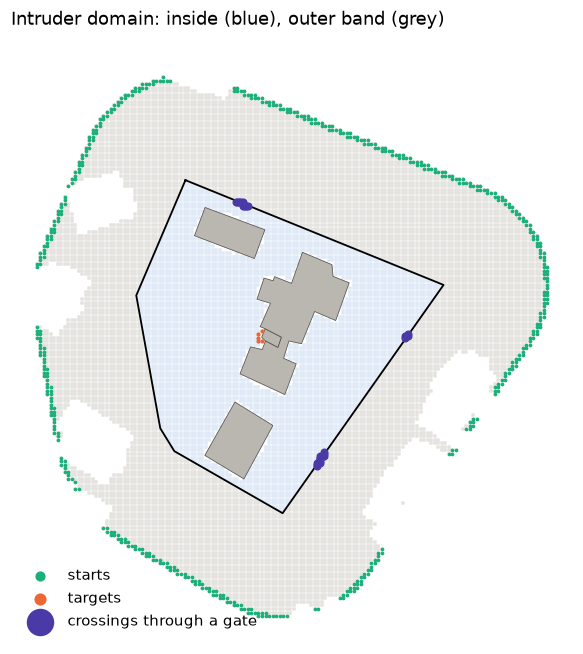

In [9]:
import geopandas as gpd

from src.intruder import PROFILES, load_domain
from src.rasters import load_grid

dom, A, conf = load_domain(cfg, ROOT)
grid = load_grid(Path(cfg["site"]["grid_yaml"]))
per = gpd.read_file(cfg["site"]["gpkg"], layer="perimeter").geometry.iloc[0]
assets = gpd.read_file(cfg["site"]["output_gpkg"], layer="assets")
print(f"{dom.n:,} cells ({dom.inside.sum():,} inside, {(~dom.inside).sum():,} in the outer band), "
      f"{dom.u.size:,} edges, of which {dom.crosses.sum():,} cross the fence and "
      f"{(dom.gate >= 0).sum()} through a gate")
print(f"starts: {dom.source.sum():,} cells, targets: {dom.target.sum():,} cells; "
      f"A_intruder: {A.shape[0]:,} configurations × {A.shape[1]:,} cells")

r, c = dom.rows, dom.cols
X = grid.xmin + (c + 0.5) * grid.res
Y = grid.ymax - (r + 0.5) * grid.res
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(X[dom.inside], Y[dom.inside], s=1, color="#dfe9f7", marker="s")
ax.scatter(X[~dom.inside], Y[~dom.inside], s=1, color="#e4e3df", marker="s")
gpd.GeoSeries(list(assets.geometry)).plot(ax=ax, color="#b9b7b0", edgecolor="#52514e", lw=0.5)
ax.plot(*per.exterior.xy, color="k", lw=1.2)
ax.scatter(X[dom.source], Y[dom.source], s=2, color="#1baf7a", label="starts")
ax.scatter(X[dom.target], Y[dom.target], s=3, color="#eb6834", label="targets")
gt = dom.gate >= 0
ax.scatter((X[dom.u[gt]] + X[dom.v[gt]]) / 2, (Y[dom.u[gt]] + Y[dom.v[gt]]) / 2, s=18,
           color="#4a3aa7", label="crossings through a gate", zorder=5)
ax.set_aspect("equal"); ax.set_axis_off(); ax.legend(frameon=False, loc="lower left", markerscale=4)
ax.set_title("Intruder domain: inside (blue), outer band (grey)", loc="left")
plt.show()

## 2. Metric 1: the corridor threshold $p^\star$

Two naive formulations are wrong: a shortest path on "cost = P" adds probabilities, and
$1 - \prod (1 - P)$ along a path counts one observation per cell, so it depends on the grid resolution.
The design metric is instead

$$
p^\star = \min_{\gamma : \text{start} \to \text{target}} \ \max_{v \in \gamma} P_v ,
$$

the detection at the **best watched point** of the **least watched corridor**. It is a guaranteed lower
bound whatever the correlation between detections along the path: "detected somewhere on $\gamma$" contains
"detected at its best point".

It is computed exactly by **percolation**: add the nodes by increasing $P$ into a union-find structure, with
a super-start linked to every start and a super-target linked to every target; $p^\star$ is the detection of
the node whose addition connects them. A toy grid with a low-detection corridor:

union-find p* = 0.243, bisection on connected components = 0.243


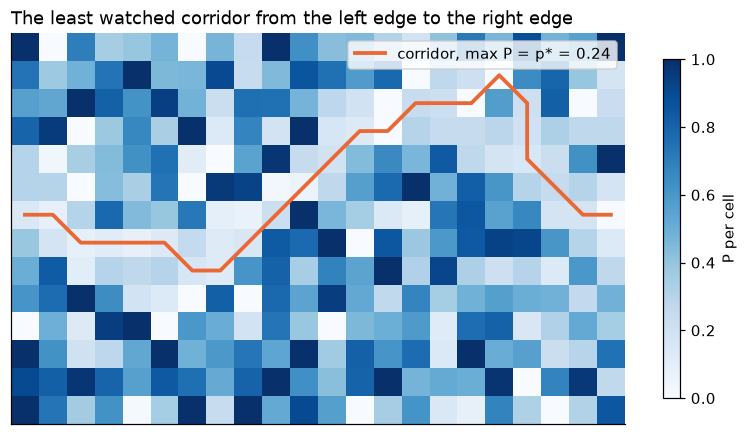

In [10]:
from scipy.sparse.csgraph import connected_components

from src.intruder import Domain, adjacency, corridor_threshold, exposure
from src.intruder_domain import build_edges
from src.site import Grid


def toy_domain(mask, source, target, inside=None, res=1.0, gate_rows=None):
    H, W = mask.shape
    g = Grid(crs="EPSG:2950", xmin=0.0, ymin=0.0, xmax=W * res, ymax=H * res, res=res)
    rows, cols = np.nonzero(mask)
    ins = np.zeros(rows.size, bool) if inside is None else inside[rows, cols]
    u, v, l, fr = build_edges(g, rows, cols, ins)
    gate = np.full(u.size, -1, np.int16)
    if gate_rows is not None:
        ext = np.where(~ins[u], u, v)
        gate[fr & np.isin(rows[ext], gate_rows)] = 0
    d = Domain(rows=rows, cols=cols, inside=ins, source=source[rows, cols], target=target[rows, cols],
               u=u, v=v, length=l, crosses=fr, gate=gate)
    return d, rows, cols


H, W = 14, 22
rng = np.random.default_rng(3)
left = np.zeros((H, W), bool); left[:, 0] = True
right = np.zeros((H, W), bool); right[:, -1] = True
toy, tr, tc = toy_domain(np.ones((H, W), bool), left, right)
P = np.clip(0.55 + 0.35 * rng.standard_normal(toy.n), 0, 1)
P[np.abs(tr - (5 + 3 * np.sin(tc / 3))) < 1.2] *= 0.3            # a winding, less watched corridor
p_star, corridor = corridor_threshold(toy, P, "F")


def p_star_by_bisection(d, P):
    for t in np.unique(P):                            # smallest t such that {P <= t} connects
        ok = P <= t
        keep = ok[d.u] & ok[d.v]
        _, lab = connected_components(adjacency(d, keep), directed=False)
        if np.isin(lab[d.source & ok], lab[d.target & ok]).any():
            return t

print(f"union-find p* = {p_star:.3f}, bisection on connected components = {p_star_by_bisection(toy, P):.3f}")
img = np.full((H, W), np.nan); img[tr, tc] = P
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(img, cmap="Blues", vmin=0, vmax=1)
ax.plot(tc[corridor], tr[corridor], color="#eb6834", lw=2.5, label=f"corridor, max P = p* = {p_star:.2f}")
ax.set_title("The least watched corridor from the left edge to the right edge", loc="left")
ax.legend(loc="upper right", frameon=True); fig.colorbar(im, ax=ax, shrink=0.8, label="P per cell")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 3. Metric 2: the exposure $\Lambda$

An estimate rather than a bound: a sensor makes an independent observation every $\tau_\text{obs}$ seconds
and the intruder spends $\Delta t_u$ seconds in cell $u$. With $\sigma_u = -\ln(1 - P_u)$,

$$
\Pr[\text{not detected on } \gamma] = \exp\Big(-\sum_{u \in \gamma} \sigma_u \frac{\Delta t_u}{\tau_\text{obs}}\Big)
= e^{-\Lambda(\gamma)}, \qquad P_\text{path} = 1 - e^{-\Lambda^\star},
$$

minimised by a multi-source Dijkstra, the time of an edge ($\ell / v$ + the crossing time) being split between
its two cells. $\Lambda$ is a Riemann sum of $\frac{1}{v\,\tau_\text{obs}}\int_\gamma \sigma\,ds$, so it does
not depend on the resolution, unlike the per-cell product:

In [11]:
IC = dict(speed_m_s=1.5, t_fence_s=10.0, t_gate_s=3.0)
rows_ = []
for res in (1.0, 0.5, 0.25):
    n = int(20 / res) + 1
    line = np.ones((1, n), bool)
    s0 = np.zeros((1, n), bool); s0[0, 0] = True
    t0 = np.zeros((1, n), bool); t0[0, -1] = True
    d, _, cc = toy_domain(line, s0, t0, res=res)
    sigma = 0.01 + 0.004 * cc * res                  # detection growing along a 20 m walk
    lam, path = exposure(d, sigma, "F", IC, 1.0)
    rows_.append(dict(cell_size_m=res, exposure_Lambda=round(lam, 4),
                      P_path=round(1 - np.exp(-lam), 4),
                      per_cell_product=round(1 - np.prod(np.exp(-sigma[path])), 4)))
pd.DataFrame(rows_)

,cell_size_m,exposure_Lambda,P_path,per_cell_product
0,1.00,0.6667,0.4866,0.6501
1,0.50,0.6667,0.4866,0.8713
2,0.25,0.6667,0.4866,0.9826


Two successive observations of the same sensor are not really independent (same occlusion, same angle), so
$\Lambda$ overestimates the detection and saturates quickly. **$p^\star$ is the design metric**, $\Lambda$ an
indicator.

## 4. The coverage optima against the intruder

The MILP and greedy solutions of notebook 04, one per budget, re-evaluated by the intruder
(`python -m src.intruder_evaluation`):

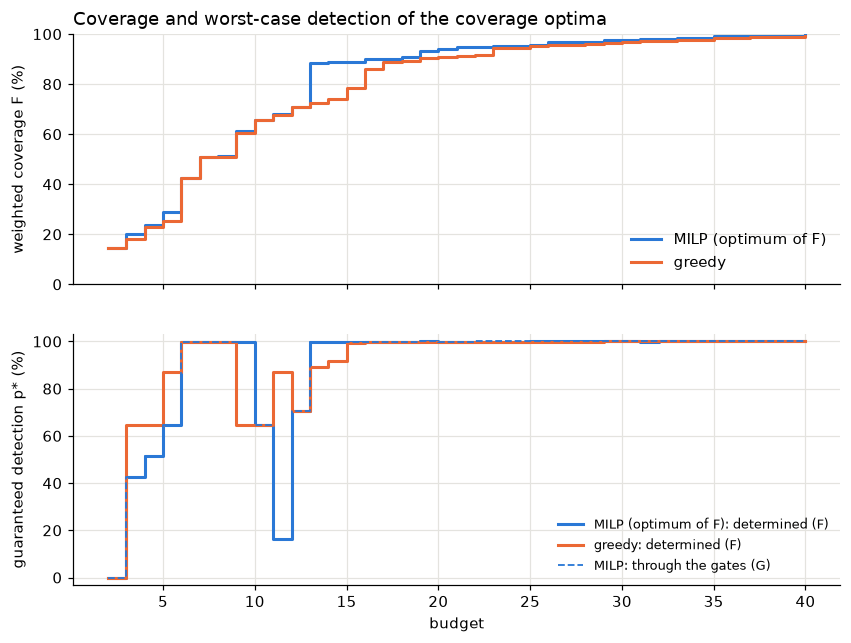

,budget,cost,F,p_star_F,p_star_G,D_pi,P_path_F_tau1
0,2.0,2.0,0.146,0.000,0.000,0.000,0.000
3,5.0,4.4,0.287,0.644,0.644,0.644,0.791
6,8.0,7.6,0.512,0.996,0.996,0.996,1.000
9,11.0,10.8,0.682,0.165,0.165,0.165,0.325
12,14.0,13.2,0.887,0.997,0.997,0.997,1.000
15,17.0,16.6,0.901,0.997,0.997,0.997,1.000
18,20.0,19.8,0.941,0.997,1.000,0.999,1.000
21,23.0,23.0,0.953,0.998,1.000,0.999,1.000
24,26.0,26.0,0.968,1.000,1.000,1.000,1.000
27,29.0,29.0,0.977,1.000,1.000,1.000,1.000


In [12]:
w3 = pd.read_csv(Path(cfg["intruder"]["out_dir"]) / "week3.csv")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
for m, col, lab in (("milp", "#2a78d6", "MILP (optimum of F)"), ("greedy", "#eb6834", "greedy")):
    d = w3[w3.method == m].sort_values("budget")
    a1.step(d.budget, 100 * d.F, where="post", color=col, lw=2, label=lab)
    a2.step(d.budget, 100 * d.p_star_F, where="post", color=col, lw=2, label=f"{lab}: determined (F)")
d = w3[w3.method == "milp"].sort_values("budget")
a2.step(d.budget, 100 * d.p_star_G, where="post", color="#2a78d6", lw=1.2, ls="--",
        label="MILP: through the gates (G)")
a1.set_ylabel("weighted coverage F (%)"); a1.set_ylim(0, 100); a1.legend(frameon=False, loc="lower right")
a2.set_ylabel("guaranteed detection p* (%)"); a2.set_ylim(-3, 103); a2.set_xlabel("budget")
a2.legend(frameon=False, loc="lower right", fontsize=8.5)
a1.set_title("Coverage and worst-case detection of the coverage optima", loc="left")
plt.show()
w3[w3.method == "milp"][["budget", "cost", "F", "p_star_F", "p_star_G", "D_pi", "P_path_F_tau1"]] \
    .iloc[::3].round(3)

At small budgets, a good coverage can leave a corridor almost unwatched. The corridors of the determined
and opportunistic intruders through the coverage optimum at one of these budgets:

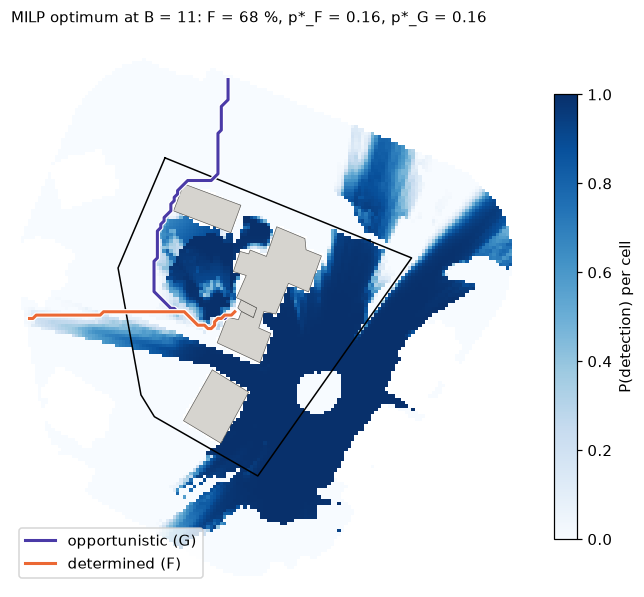

In [13]:
from src.intruder import evaluate_intruder, solutions_w3

sols = solutions_w3(conf, Path(cfg["optimization"]["out_dir"]) / "milp_solutions.csv")
milp_rows = w3[w3.method == "milp"].set_index("budget")
B = float(milp_rows[milp_rows.F > 0.5].p_star_F.idxmin())       # the weakest one above 50 % coverage
res, P, paths = evaluate_intruder(dom, A, sols[B], cfg["intruder"], paths=True)
img = np.full((grid.height, grid.width), np.nan); img[r, c] = P
r0, r1, c0, c1 = r.min() - 3, r.max() + 4, c.min() - 3, c.max() + 4
ext = (grid.xmin + c0, grid.xmin + c1, grid.ymax - r1, grid.ymax - r0)
fig, ax = plt.subplots(figsize=(7.5, 7))
im = ax.imshow(img[r0:r1, c0:c1], extent=ext, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
gpd.GeoSeries(list(assets.geometry)).plot(ax=ax, color="#d6d4cf", edgecolor="#52514e", lw=0.4)
ax.plot(*per.exterior.xy, color="k", lw=1)
for key, col, lab in (("corridor_G", "#4a3aa7", "opportunistic (G)"), ("corridor_F", "#eb6834",
                                                                        "determined (F)")):
    p = paths[key]
    ax.plot(X[p], Y[p], color="white", lw=3.5); ax.plot(X[p], Y[p], color=col, lw=2, label=lab)
fig.colorbar(im, ax=ax, shrink=0.75, label="P(detection) per cell")
ax.set_title(f"MILP optimum at B = {B:g}: F = {100 * milp_rows.F[B]:.0f} %, "
             f"p*_F = {res['p_star_F']:.2f}, p*_G = {res['p_star_G']:.2f}", loc="left", fontsize=10)
ax.legend(frameon=True, loc="lower left"); ax.set_axis_off()
plt.show()

## 5. NSGA-II: cost, coverage and worst case together

A single-objective optimum cannot expose the trade-off, so NSGA-II (pymoo) searches the Pareto front of
three objectives: cost ↓, $F$ ↑, $p^\star_F$ ↑. Solutions are very sparse (a few bits out of thousands), so the
operators work on sets: the crossover keeps each configuration of the union of the parents with probability
1/2, the mutation adds, removes, replaces or moves a sensor to a neighbouring configuration (same location),
and a random repair enforces (C3), (C4) and the budget. The population is seeded with the solutions above.

Validated against notebook 04: no point of the front may exceed the certified upper bound on (cost, F).

176 non-dominated solutions; points above the certified UB: 0


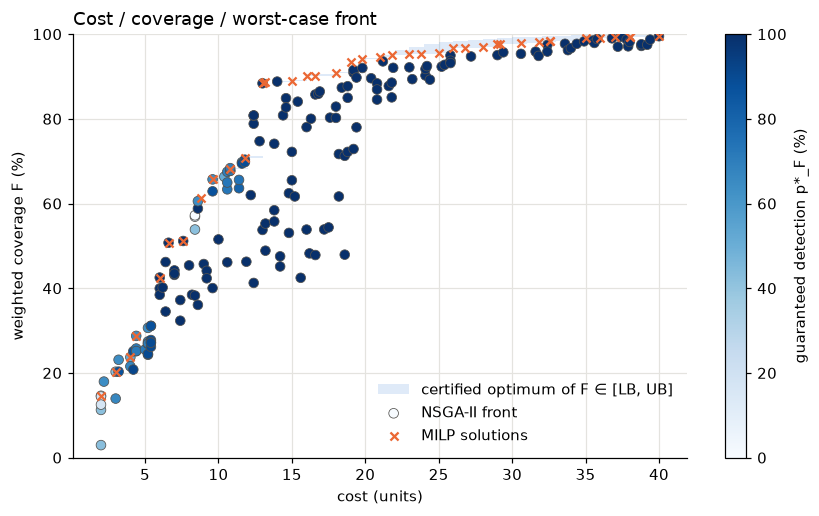

cheapest layout with p*_F ≥ 0.9: 4.2 units (0 radar(s), 3 camera(s))


,budget,F_max,F_max_p0.9,price_p0.9_pt
0,2.0,0.146,NaN,NaN
4,6.0,0.425,0.425,0.000
8,10.0,0.657,0.613,4.364
12,14.0,0.888,0.888,0.000
16,18.0,0.908,0.908,0.000
20,22.0,0.950,0.950,0.000
24,26.0,0.968,0.968,0.000
28,30.0,0.977,0.977,0.000


In [14]:
nsga_dir = Path(cfg["nsga"]["out_dir"])
front = pd.read_csv(nsga_dir / "front_global.csv")
pareto = pd.read_csv(Path(cfg["optimization"]["out_dir"]) / "pareto.csv")
print(f"{len(front)} non-dominated solutions; points above the certified UB: "
      f"{int((front.F > front.ub + 1e-9).sum())}")
fig, ax = plt.subplots(figsize=(9, 5))
b = pareto.sort_values("budget")
ax.fill_between(b.budget, 100 * b.lb, 100 * b.ub, step="post", color="#2a78d6", alpha=0.15, lw=0,
                label="certified optimum of F ∈ [LB, UB]")
sc_ = ax.scatter(front.cost, 100 * front.F, c=100 * front.p_star_F, cmap="Blues", vmin=0, vmax=100, s=40,
                 edgecolor="#52514e", lw=0.5, zorder=3, label="NSGA-II front")
m = w3[w3.method == "milp"]
ax.scatter(m.cost, 100 * m.F, marker="x", s=28, color="#eb6834", zorder=4, label="MILP solutions")
fig.colorbar(sc_, ax=ax, label="guaranteed detection p*_F (%)")
ax.set_xlabel("cost (units)"); ax.set_ylabel("weighted coverage F (%)"); ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Cost / coverage / worst-case front", loc="left")
plt.show()

price = pd.read_csv(nsga_dir / "price_of_robustness.csv")
robust = front[front.p_star_F >= 0.9]
print(f"cheapest layout with p*_F ≥ 0.9: {robust.cost.min():.1f} units "
      f"({int(robust.loc[robust.cost.idxmin(), 'n_radar'])} radar(s), "
      f"{int(robust.loc[robust.cost.idxmin(), 'n_camera'])} camera(s))")
price[["budget", "F_max", "F_max_p0.9", "price_p0.9_pt"]].iloc[::4].round(3)

Robustness has a **threshold, not a cost**: below a budget, no layout guarantees $p^\star_F \ge 0.9$; above
it, requiring it costs little coverage. What NSGA-II finds, the adversarial loop of
[06. Timely detection and the adversarial loop](06_timely_detection_and_adversarial_loop.ipynb) proves, and
it also asks whether the detection comes **in time**.